# 05 · Clustering pixels and building superpixels

**Level:** intermediate. **Time:** 60–75 minutes. **Prerequisites:** RGB arrays, masks, reshape, and basic distance intuition. This notebook is independent, deterministic, offline, and CPU-friendly.

**You will:** fit K-means to color features; understand why cluster IDs are arbitrary; score partitions appropriately; add coordinates to features; generate SLIC superpixels; compress each superpixel to a region descriptor.

**Key distinction:** grouping similar pixels is not the same as recognizing semantic categories such as person, road, or tumor.


In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "learning" / "data.py").is_file()), None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the complete ImageSegmentationPractical folder.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 3.5), "image.cmap": "gray",
                     "axes.spines.top": False, "axes.spines.right": False})
print("Project:", PROJECT_ROOT.name)


Project: ImageSegmentationPractical


## 1. From an image to a feature table

K-means expects one row per sample and one column per feature. A 96 × 96 RGB image becomes a 9,216 × 3 table. We generate a scene with background, disk, and rectangle classes; its construction mask is available for a controlled evaluation. Pixels are correlated samples, so random pixel splits would not establish performance on new images.


In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from skimage import color, segmentation, data, util
from learning.data import make_scene, palette_mask
import pandas as pd

image, truth, instance_truth = make_scene(seed=15, size=96, noise=0.08)
height, width, channels = image.shape
rgb_features = image.reshape(-1, channels)
print("Image shape:", image.shape, "feature table:", rgb_features.shape)
print("Construction classes:", np.unique(truth))

def show_grid(images, titles, columns=3, cmap="gray", limits=None):
    """A small display helper; every array is still available for inspection."""
    rows = (len(images) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(4 * columns, 3.4 * rows), squeeze=False)
    for ax, image, title in zip(axes.flat, images, titles):
        kwargs = {} if limits is None else {"vmin": limits[0], "vmax": limits[1]}
        ax.imshow(image, cmap=cmap, **kwargs)
        ax.set_title(title)
        ax.axis("off")
    for ax in list(axes.flat)[len(images):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


Image shape: (96, 96, 3) feature table: (9216, 3)
Construction classes: [0 1 2]


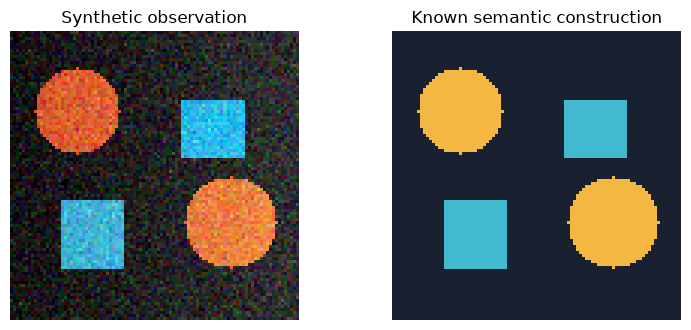

In [3]:
show_grid([image, palette_mask(truth)], ["Synthetic observation", "Known semantic construction"], columns=2)


## 2. Fit a color clustering model

K-means alternates between assigning each sample to a nearby center and updating centers. `n_clusters=3` is a deliberate hypothesis here; we know the synthetic scene contains three color groups. A fixed seed makes the demonstration repeatable. Several initializations reduce dependence on an unlucky starting arrangement.

The reconstructed image replaces every pixel with its center color. It is a color quantization, not a class prediction.


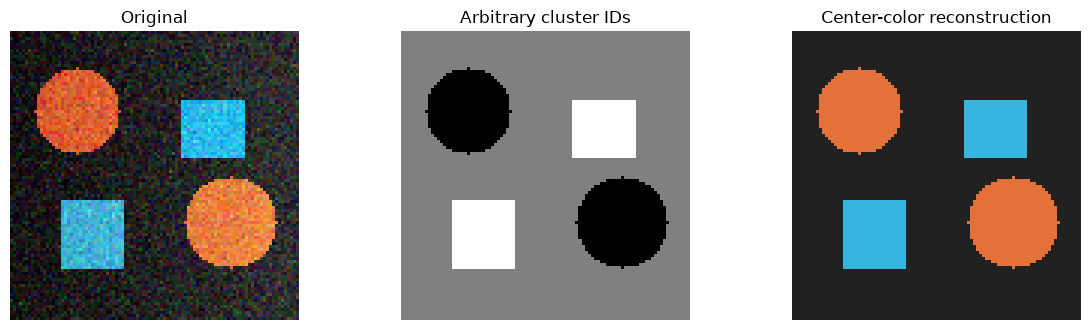

RGB cluster centers:


,R,G,B
0,0.895,0.445,0.223
1,0.134,0.133,0.134
2,0.215,0.715,0.872


In [4]:
kmeans = KMeans(n_clusters=3, random_state=0, n_init=5)
cluster_ids = kmeans.fit_predict(rgb_features).reshape(height, width)
quantized = kmeans.cluster_centers_[cluster_ids]
show_grid([image, cluster_ids, quantized], ["Original", "Arbitrary cluster IDs", "Center-color reconstruction"])
print("RGB cluster centers:")
display(pd.DataFrame(kmeans.cluster_centers_, columns=["R", "G", "B"]).round(3))


## 3. Labels can be permuted without changing a partition

Cluster 0 does not mean background and cluster 1 does not mean disk. If we rename every cluster, the grouping is unchanged. Raw pixel accuracy between cluster IDs and semantic IDs is therefore invalid.

**Adjusted Rand index (ARI)** compares which pairs of pixels are grouped together. It is invariant to ID permutation: 1 means identical partitions, around 0 is chance-level agreement under its adjustment, and negative values are possible. Here it measures partition agreement with our synthetic classes; it does not prove semantic understanding.


Original ARI: 1.0000; renamed ARI: 1.0000
The groups did not change when their IDs changed.


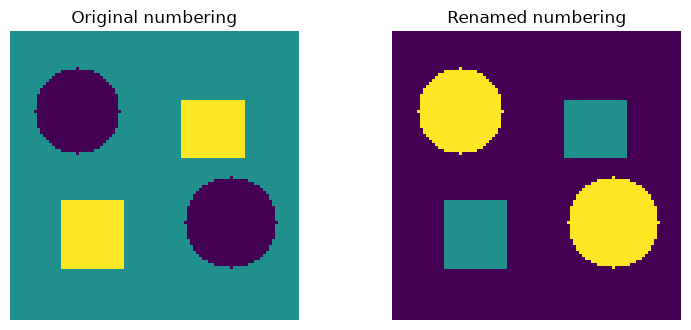

In [5]:
permutation = np.array([2, 0, 1])
renamed_clusters = permutation[cluster_ids]
original_ari = adjusted_rand_score(truth.ravel(), cluster_ids.ravel())
renamed_ari = adjusted_rand_score(truth.ravel(), renamed_clusters.ravel())
print(f"Original ARI: {original_ari:.4f}; renamed ARI: {renamed_ari:.4f}")
assert np.isclose(original_ari, renamed_ari)
print("The groups did not change when their IDs changed.")
show_grid([cluster_ids, renamed_clusters], ["Original numbering", "Renamed numbering"], columns=2, cmap="viridis")


## 4. Experiment: choosing the number of groups

Try too few, plausible, and too many clusters. K-means inertia measures squared feature distance within clusters; it tends to decrease as more clusters are allowed. It is **not** semantic accuracy. ARI uses the construction mask as a diagnostic; do not tune on a real test set this way.


,k,inertia,ARI_to_construction
0,2,703.317,0.942
1,3,197.544,1.000
2,5,137.545,0.319


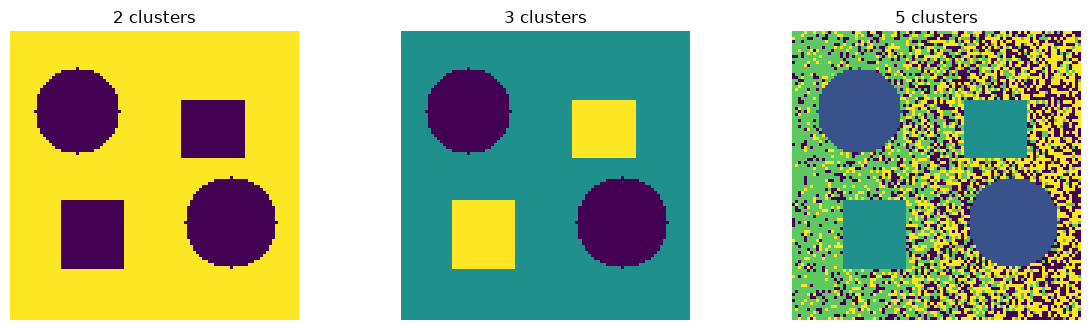

In [6]:
records, clusterings = [], []
for k in (2, 3, 5):
    model = KMeans(n_clusters=k, random_state=0, n_init=3)
    partition = model.fit_predict(rgb_features).reshape(height, width)
    clusterings.append(partition)
    records.append({"k": k, "inertia": model.inertia_,
                    "ARI_to_construction": adjusted_rand_score(truth.ravel(), partition.ravel())})
display(pd.DataFrame(records).round(3))
show_grid(clusterings, ["2 clusters", "3 clusters", "5 clusters"], cmap="viridis")


## 5. Feature engineering: color plus position

RGB distance is convenient but does not closely match perceptual color differences. We use Lab color features and divide them by 100 to keep their scale manageable. Coordinates normalized to 0–1 add a preference for nearby pixels. `spatial_weight` controls that preference; a large weight can split one uniform object by location.

These features express assumptions. There is no universally correct scale balance.


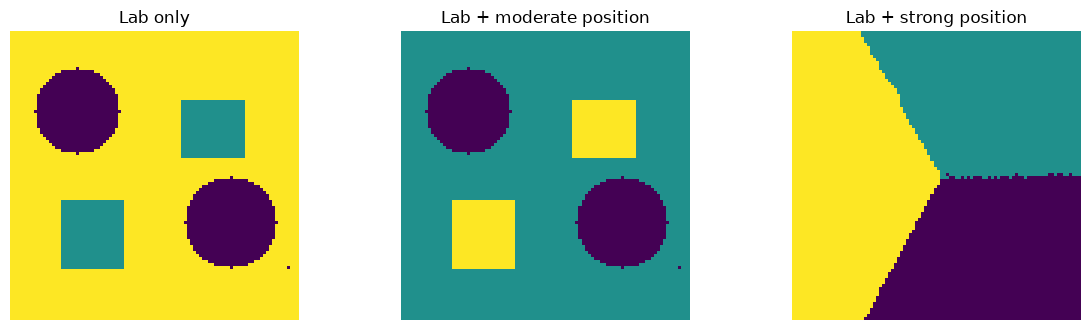

In [7]:
lab_features = color.rgb2lab(image).reshape(-1, 3) / 100.0
yy, xx = np.mgrid[:height, :width]
coordinates = np.column_stack((yy.ravel() / (height - 1), xx.ravel() / (width - 1)))
spatial_partitions = []
for spatial_weight in (0.0, 0.5, 3.0):
    features = np.column_stack((lab_features, spatial_weight * coordinates))
    partition = KMeans(n_clusters=3, random_state=0, n_init=3).fit_predict(features).reshape(height, width)
    spatial_partitions.append(partition)
show_grid(spatial_partitions, ["Lab only", "Lab + moderate position", "Lab + strong position"], cmap="viridis")


## 6. SLIC: intentionally oversegment the image

Superpixels are small coherent regions intended to preserve useful image boundaries. One semantic object usually contains many superpixels. SLIC combines color and spatial proximity while producing local regions. `n_segments` is an approximate requested count; connectivity cleanup can change the actual count.

We set `channel_axis=-1` for RGB and start IDs at 0. Superpixel boundaries are shown over the image; they are not annotations.


Requested 90 superpixels; actual count: 74


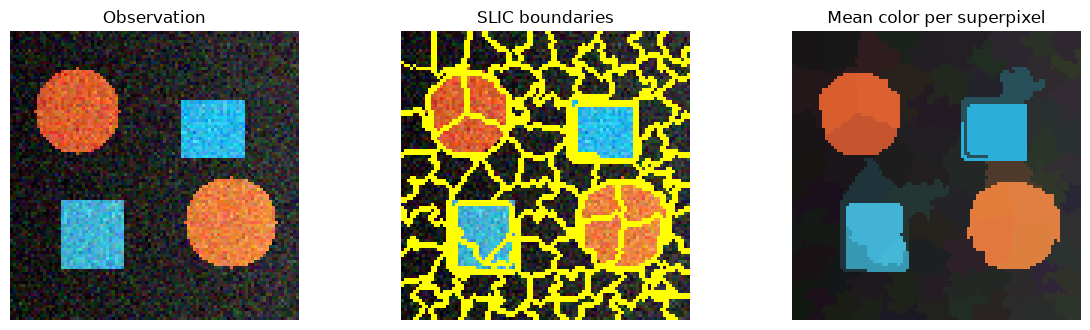

In [8]:
superpixels = segmentation.slic(image, n_segments=90, compactness=10,
                                sigma=1, start_label=0, channel_axis=-1)
boundary_overlay = segmentation.mark_boundaries(image, superpixels, color=(1, 1, 0))
superpixel_means_image = color.label2rgb(superpixels, image, kind="avg", bg_label=-1)
print("Requested 90 superpixels; actual count:", np.unique(superpixels).size)
show_grid([image, boundary_overlay, superpixel_means_image],
          ["Observation", "SLIC boundaries", "Mean color per superpixel"])


## 7. Compactness trades color fit for regularity

Low compactness lets regions follow color variation more strongly. High compactness emphasizes spatial regularity. Compare whether boundaries follow object edges and how much each object is subdivided. A clean grid is not necessarily a useful segmentation.


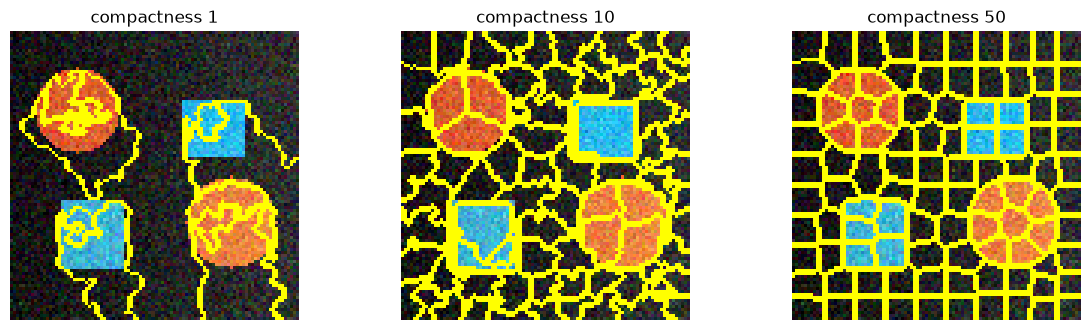

In [9]:
slic_overlays = []
for compactness in (1, 10, 50):
    labels = segmentation.slic(image, n_segments=90, compactness=compactness,
                               sigma=1, start_label=0, channel_axis=-1)
    slic_overlays.append(segmentation.mark_boundaries(image, labels, color=(1, 1, 0)))
show_grid(slic_overlays, ["compactness 1", "compactness 10", "compactness 50"])


## 8. Compress pixels into region features

Represent every superpixel by its mean RGB color, then cluster those region descriptors. We use pixel-count weights so a larger region contributes more than a tiny one. Mapping region-cluster IDs back to pixels creates a coarser partition. This can stabilize noisy colors, but any superpixel that crosses a true boundary carries an irreversible mixing error in this simple pipeline.


Pixel rows: 9,216; region rows: 74
Region pipeline ARI: 0.885


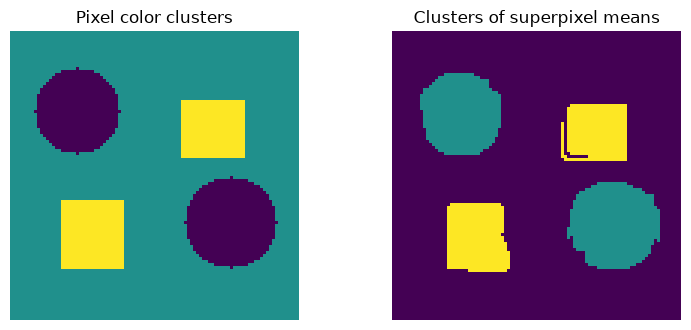

In [10]:
region_ids, inverse = np.unique(superpixels.ravel(), return_inverse=True)
pixel_counts = np.bincount(inverse)
mean_rgb = np.column_stack([
    np.bincount(inverse, weights=image[..., channel].ravel()) / pixel_counts
    for channel in range(3)
])
region_model = KMeans(n_clusters=3, random_state=0, n_init=5)
region_model.fit(mean_rgb, sample_weight=pixel_counts)
region_clusters = region_model.labels_
region_partition = region_clusters[inverse].reshape(height, width)
print(f"Pixel rows: {height * width:,}; region rows: {len(region_ids)}")
print(f"Region pipeline ARI: {adjusted_rand_score(truth.ravel(), region_partition.ravel()):.3f}")
show_grid([cluster_ids, region_partition], ["Pixel color clusters", "Clusters of superpixel means"],
          columns=2, cmap="viridis")


## 9. Transfer to a real photograph

The astronaut image is bundled with scikit-image. We subsample to 128 × 128 so this is a quick local experiment. SLIC groups appearance; it does not identify the astronaut. No annotated mask is provided, so this step reports region counts and visual observations only.


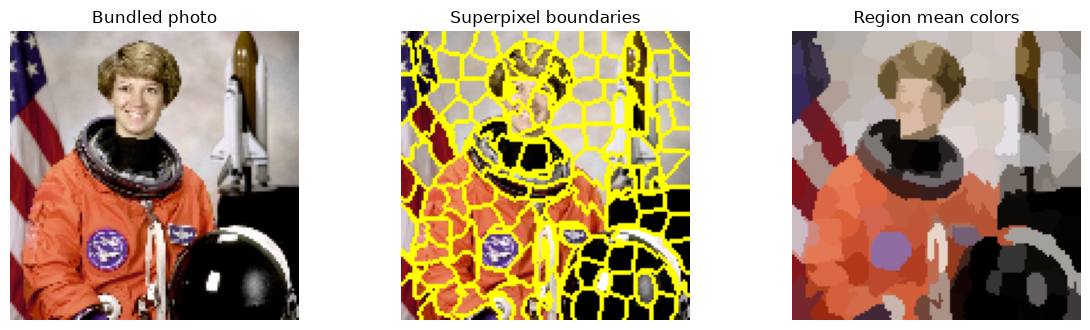

Real-photo superpixels: 136
Inspect the face, dark background, and bright suit for boundary leakage.


In [11]:
photo = util.img_as_float(data.astronaut()[::4, ::4])
photo_regions = segmentation.slic(photo, n_segments=150, compactness=12,
                                  sigma=1, start_label=0, channel_axis=-1)
show_grid([photo, segmentation.mark_boundaries(photo, photo_regions),
           color.label2rgb(photo_regions, photo, kind="avg", bg_label=-1)],
          ["Bundled photo", "Superpixel boundaries", "Region mean colors"])
print("Real-photo superpixels:", np.unique(photo_regions).size)
print("Inspect the face, dark background, and bright suit for boundary leakage.")


## 10. Exercises

**A. Prove permutation invariance.** Randomly rename all SLIC region IDs and compare ARI between the original and renamed arrays. Why should it be exactly 1?

<details><summary>Worked solution A</summary>

```python
ids, dense = np.unique(superpixels.ravel(), return_inverse=True)
renaming = np.random.default_rng(9).permutation(len(ids))
renamed = renaming[dense].reshape(superpixels.shape)
print(adjusted_rand_score(superpixels.ravel(), renamed.ravel()))
```
Every pair of pixels stays together or stays apart. Only the names change.
</details>


**B. Superpixel scale.** Try 30, 100, and 300 requested regions on `photo`. Record actual counts and one boundary that improves or worsens.

<details><summary>Worked solution B</summary>

```python
overlays, titles = [], []
for count in (30, 100, 300):
    labels = segmentation.slic(photo, n_segments=count, compactness=12,
                               sigma=1, start_label=0, channel_axis=-1)
    overlays.append(segmentation.mark_boundaries(photo, labels))
    titles.append(f"requested={count}, actual={np.unique(labels).size}")
show_grid(overlays, titles)
```
More regions can preserve finer details at the cost of more descriptors and more fragmentation. They do not automatically create semantic labels.
</details>


**C. Build a region table.** Save one row per superpixel with its ID, size, and mean RGB. Confirm that all region sizes sum to the image pixel count.

<details><summary>Worked solution C</summary>

```python
region_table = pd.DataFrame({"region_id": region_ids, "pixels": pixel_counts,
                             "mean_R": mean_rgb[:, 0], "mean_G": mean_rgb[:, 1],
                             "mean_B": mean_rgb[:, 2]})
assert region_table["pixels"].sum() == height * width
destination = PROJECT_ROOT / "outputs" / "05_superpixel_features.csv"
destination.parent.mkdir(parents=True, exist_ok=True)
region_table.to_csv(destination, index=False)
display(region_table.head())
```
This table could feed a supervised region classifier when labeled training regions are available. That is a new learning task, not an automatic semantic interpretation of cluster IDs.
</details>


## Common mistakes and completion checklist

- Never equate K-means IDs with semantic IDs without a justified mapping learned independently of the test labels.
- A lower inertia value does not mean a better semantic segmentation.
- Unscaled coordinates can overwhelm color features.
- Superpixels are a representation; they are usually not the final objects.
- ARI evaluates the whole partition and can obscure particular rare-class failures. Inspect classes and boundaries too.
- Image-level train/validation/test separation is needed when evaluating generalization.

- [ ] I can reshape an image into samples and features and reconstruct it.
- [ ] I demonstrated why cluster ID accuracy is meaningless.
- [ ] I can explain the effect of spatial weight and compactness.
- [ ] I produced a table of region descriptors.
- [ ] I completed the three exercises and recorded one failure case.

**Next:** learn careful segmentation evaluation before training supervised models.


## Official references

- [scikit-learn KMeans API](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)
- [Adjusted Rand score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html)
- [scikit-image SLIC API](https://scikit-image.org/docs/stable/api/skimage.segmentation.html#skimage.segmentation.slic)
- [Comparison of segmentation and superpixel algorithms](https://scikit-image.org/docs/stable/auto_examples/segmentation/plot_segmentations.html)
- [RGB to Lab conversion](https://scikit-image.org/docs/stable/api/skimage.color.html#skimage.color.rgb2lab)

All links are optional reading; the executable path uses no web downloads.
